In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

In [2]:
df = pd.read_csv("heart-checkpoint.csv")

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [6]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [7]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


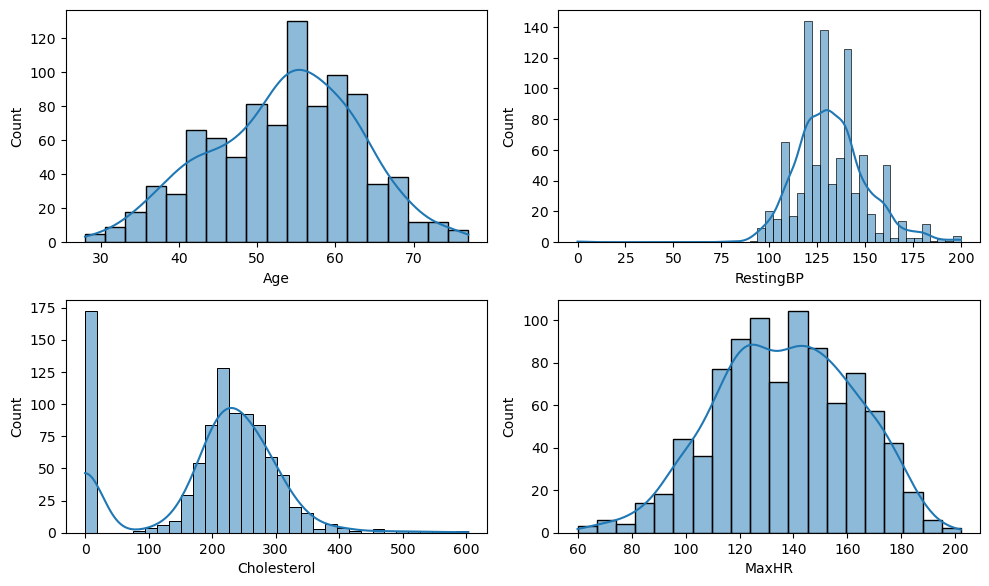

In [8]:
plt.figure(figsize=(10,6))
def plotting(var,num):
    plt.subplot(2,2,num)
    sns.histplot(df[var],kde=True)

plotting("Age",1)
plotting("RestingBP",2)
plotting("Cholesterol",3)
plotting("MaxHR",4)

plt.tight_layout()



In [9]:
(df['Cholesterol'] == 0).sum()

np.int64(172)

In [10]:
(df['RestingBP'] <= 70).sum()

np.int64(1)

In [11]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [12]:
df["FastingBS"].value_counts()

FastingBS
0    704
1    214
Name: count, dtype: int64

In [13]:
df_encode = pd.get_dummies(df,columns=['Sex','ChestPainType','RestingECG','ExerciseAngina','ST_Slope'],drop_first=True)
df_encode.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140,289,0,172,0.0,0,True,True,False,False,True,False,False,False,True
1,49,160,180,0,156,1.0,1,False,False,True,False,True,False,False,True,False
2,37,130,283,0,98,0.0,0,True,True,False,False,False,True,False,False,True
3,48,138,214,0,108,1.5,1,False,False,False,False,True,False,True,True,False
4,54,150,195,0,122,0.0,0,True,False,True,False,True,False,False,False,True


In [14]:
col = df_encode.drop("Oldpeak",axis=1)

In [15]:
col = col.astype(int)
col['Oldpeak'] = df_encode['Oldpeak']

In [16]:
col

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up,Oldpeak
0,40,140,289,0,172,0,1,1,0,0,1,0,0,0,1,0.0
1,49,160,180,0,156,1,0,0,1,0,1,0,0,1,0,1.0
2,37,130,283,0,98,0,1,1,0,0,0,1,0,0,1,0.0
3,48,138,214,0,108,1,0,0,0,0,1,0,1,1,0,1.5
4,54,150,195,0,122,0,1,0,1,0,1,0,0,0,1,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,110,264,0,132,1,1,0,0,1,1,0,0,1,0,1.2
914,68,144,193,1,141,1,1,0,0,0,1,0,0,1,0,3.4
915,57,130,131,0,115,1,1,0,0,0,1,0,1,1,0,1.2
916,57,130,236,0,174,1,0,1,0,0,0,0,0,1,0,0.0


In [17]:
X = col.drop('HeartDisease',axis=1)
y = col['HeartDisease']

In [18]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42,stratify=y)


In [19]:
chol_median_train =  X_train.loc[X_train['Cholesterol'] != 0,'Cholesterol'].median()
resting_median_train =  X_train.loc[X_train['RestingBP'] != 0,'RestingBP'].median()

chol_median_test =  X_train.loc[X_train['Cholesterol'] != 0,'Cholesterol'].median()
resting_median_test =  X_train.loc[X_train['RestingBP'] != 0,'RestingBP'].median()

In [20]:
X_train['Cholesterol'] = X_train['Cholesterol'].replace(0,chol_median_train)
X_train['RestingBP']= X_train['RestingBP'].replace(0,resting_median_train)

X_test['Cholesterol'] = X_test['Cholesterol'].replace(0,chol_median_test)
X_test['RestingBP']= X_test['RestingBP'].replace(0,resting_median_test)

In [21]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=2000)
model.fit(X_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,2000
,multi_class,'deprecated'


In [22]:
y_probab = model.predict_proba(X_test)[:,1]

In [23]:
threshold =  0.4
y_predict = (y_probab >= threshold)

Is line ka matlab: probability 0.4 ya usse zyada ho to 1 (beemar), warna 0 (healthy).

In [24]:
y_probab1 = model.predict_proba(X_train)[:,1]
threshold =  0.4
y_predict1 = (y_probab1 >= threshold)

In [25]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report,roc_auc_score,ConfusionMatrixDisplay
print("Test data Accuracy : ",accuracy_score(y_test,y_predict))

Test data Accuracy :  0.8804347826086957


In [26]:
print("Train data Accuracy : ",accuracy_score(y_train,y_predict1))

Train data Accuracy :  0.8664850136239782


In [27]:
print("test data roc_auc : ",roc_auc_score(y_test,y_probab))

test data roc_auc :  0.9330463892874222


In [28]:
print("train data roc_auc : ",roc_auc_score(y_train,y_probab1))

train data roc_auc :  0.9278805719091674


In [29]:
confusion_matrix(y_test,y_predict)

array([[66, 16],
       [ 6, 96]])

In [30]:
print(classification_report(y_test,y_predict))

              precision    recall  f1-score   support

           0       0.92      0.80      0.86        82
           1       0.86      0.94      0.90       102

    accuracy                           0.88       184
   macro avg       0.89      0.87      0.88       184
weighted avg       0.88      0.88      0.88       184



In [31]:
joblib.dump(model,"heart-disease_model.pkl")

['heart-disease_model.pkl']

In [32]:
X_train

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up,Oldpeak
485,63,139,217,1,128,1,1,0,0,0,1,1,1,0,1.2
486,55,110,214,1,180,1,1,0,0,0,1,0,0,1,0.4
117,59,130,338,1,130,0,0,0,0,0,1,1,1,0,1.5
361,47,160,238,0,124,1,0,0,0,1,0,1,1,0,0.0
296,50,145,238,1,139,1,0,0,0,1,0,1,1,0,0.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
276,51,135,160,0,150,1,0,1,0,1,0,0,1,0,2.0
201,46,120,230,0,150,1,0,1,0,1,0,0,0,1,0.0
462,59,122,233,0,117,1,0,0,0,1,0,1,0,0,1.3
252,61,125,292,0,115,1,0,0,0,0,1,1,0,1,0.0


In [33]:
df

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1


In [34]:
bundle = {'model': model, 'columns': list(X_train.columns),
          'chol_median': chol_median_train, 'bp_median': resting_median_train,
          'threshold': threshold}
joblib.dump(bundle, 'heart_bundle.joblib')

['heart_bundle.joblib']

In [35]:
bundle = joblib.load("heart_bundle.joblib")

new_patient = pd.DataFrame([{
    "Age":48,"Sex":"F","ChestPainType":"ASY","RestingBP":138,"Cholesterol":214,"FastingBS":0,"RestingECG":"Normal","MaxHR":108,"ExerciseAngina":"Y",
    "Oldpeak":1.5,"ST_Slope":"Flat"}])

new_patient['Cholesterol'] = new_patient['Cholesterol'].replace(0, bundle['chol_median'])
new_patient['RestingBP']   = new_patient['RestingBP'].replace(0, bundle['bp_median'])

new_patient = pd.get_dummies(new_patient)
new_patient = new_patient.reindex(columns=bundle['columns'], fill_value=0)

In [36]:
prob = bundle['model'].predict_proba(new_patient)[0, 1]
print("Probability:", round(prob * 100, 1), "%")
print("Result:", "Heart Disease" if prob >= bundle['threshold'] else "No Heart Disease")


Probability: 83.6 %
Result: Heart Disease
